<a href="https://colab.research.google.com/github/maulidyaafriani/PCVK_Genap_2026/blob/main/Week6_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**JOBSHEET MODUL 6** – Filter Spasial Low Pass Filter, High Pass Filter, Point

Detection, Line Detection, Edge Detection

In [ ]:
NAMA = 'Maulidya Afriani'
NIM  = '24410700059'
print(NAMA, NIM)

Maulidya Afriani 24410700059


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**PRAKTIKUM FILTER**

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

In [ ]:
def convolution2d(image, kernel, stride, padding):
    image = image.astype(np.float64)
    kh, kw = kernel.shape

    if padding > 0:
        image = np.pad(image, padding, mode='constant', constant_values=0)

    H, W = image.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    out = np.zeros((out_h, out_w))

    for i in range(out_h):
        for j in range(out_w):
            y, x = i * stride, j * stride
            out[i, j] = np.sum(image[y:y+kh, x:x+kw] * kernel)
    return out

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020059/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

In [ ]:
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

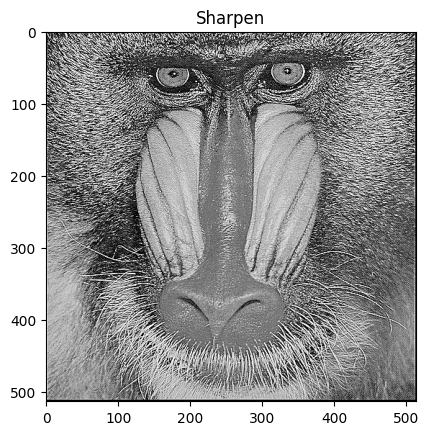

In [ ]:
hasil = convolution2d(img_gray, kernel_sharpen, 1, 2)
hasil = np.clip(hasil, 0, 255).astype(np.uint8)

plt.imshow(hasil, cmap='gray')
plt.title('Sharpen')
plt.show()

In [ ]:
def filter_citra(image, kernel, mode='clip'):
    pad = kernel.shape[0] // 2
    hasil = convolution2d(image, kernel, 1, pad)
    if mode == 'abs':
        hasil = np.abs(hasil)
    elif mode == 'offset':
        hasil = hasil + 128
    return np.clip(hasil, 0, 255).astype(np.uint8)

def tampil(hasil, judul):
    plt.figure(figsize=(6,6))
    plt.imshow(hasil, cmap='gray', vmin=0, vmax=255)
    plt.title(judul)
    plt.show()

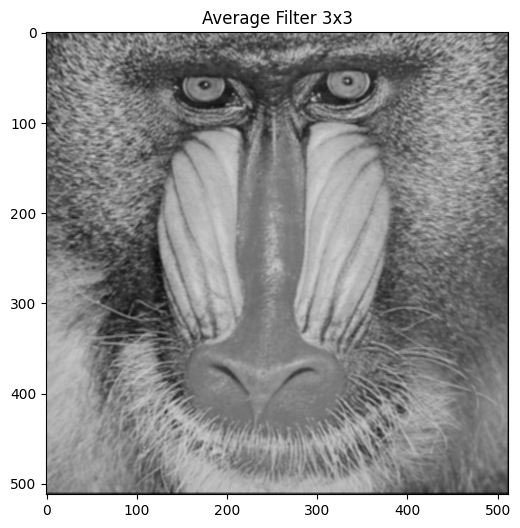

In [ ]:
average_3x3 = np.ones((3,3)) / 9
tampil(filter_citra(img_gray, average_3x3), 'Average Filter 3x3')

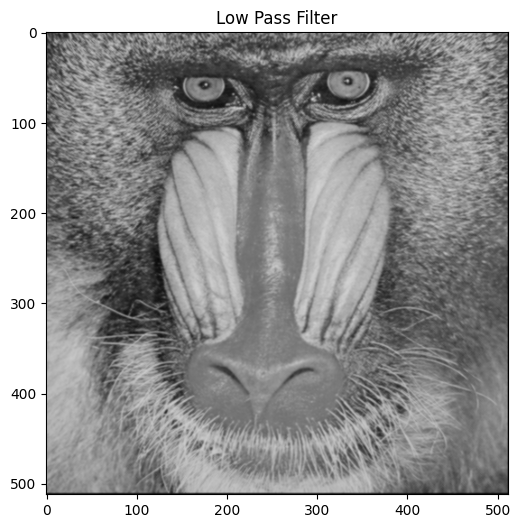

In [ ]:
low_pass = np.array([[1,1,1],
                     [1,4,1],
                     [1,1,1]]) / 12
tampil(filter_citra(img_gray, low_pass), 'Low Pass Filter')

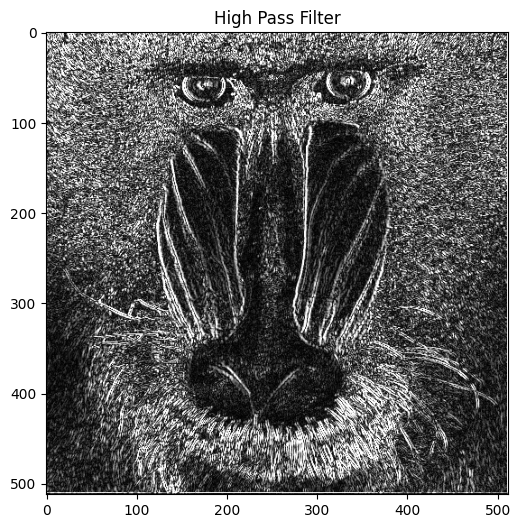

In [ ]:
high_pass = np.array([[-1,0,1],
                      [-1,0,3],
                      [-3,0,1]])
tampil(filter_citra(img_gray, high_pass, 'abs'), 'High Pass Filter')

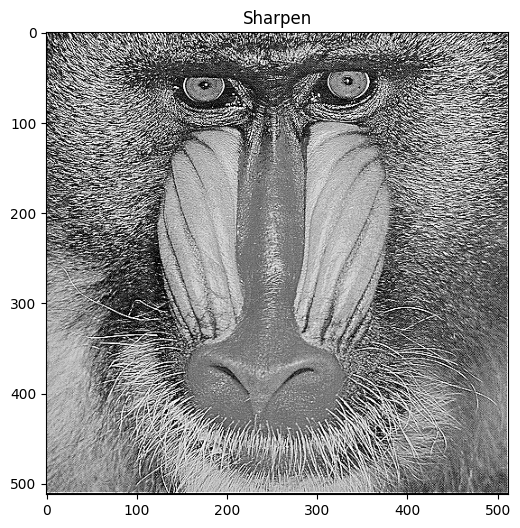

In [ ]:
tampil(filter_citra(img_gray, kernel_sharpen), 'Sharpen')

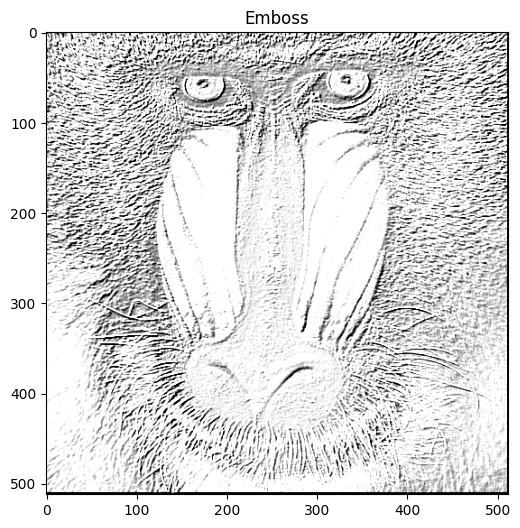

In [ ]:
emboss = np.array([[-2,-1,0],
                   [-1,1,1],
                   [0,1,2]])
tampil(filter_citra(img_gray, emboss, 'offset'), 'Emboss')

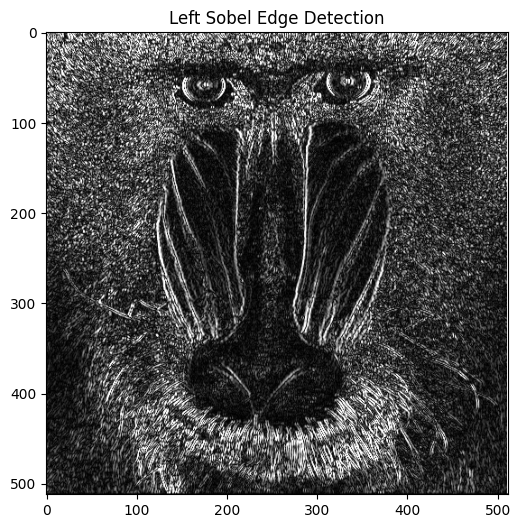

In [ ]:
left_sobel = np.array([[1,0,-1],
                       [2,0,-2],
                       [1,0,-1]])
tampil(filter_citra(img_gray, left_sobel, 'abs'), 'Left Sobel Edge Detection')

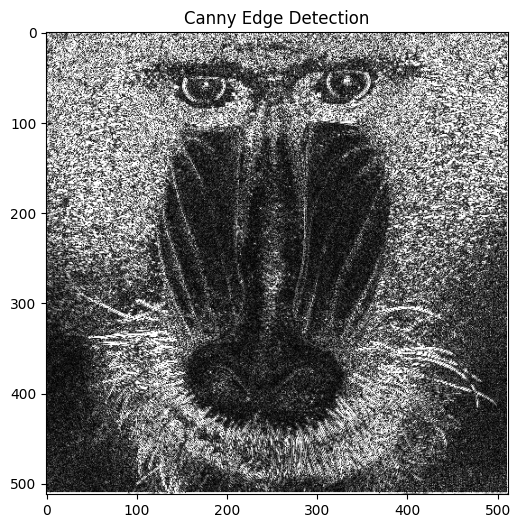

In [ ]:
canny_kernel = np.array([[-1,-1,-1],
                         [-1,8,-1],
                         [-1,-1,-1]])
tampil(filter_citra(img_gray, canny_kernel, 'abs'), 'Canny Edge Detection')

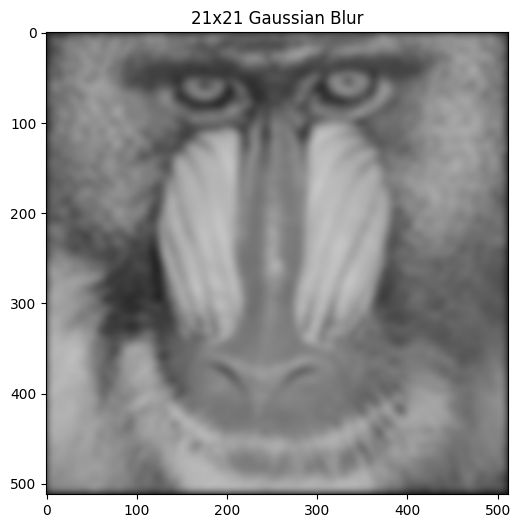

In [ ]:
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()
tampil(filter_citra(img_gray, gauss_kernel), '21x21 Gaussian Blur')

**FILTER LIBRARY DAN FILTER MODERN**



In [ ]:
import os
print(os.path.exists('/content/drive/MyDrive'))

True


In [ ]:
import glob
hasil = glob.glob('/content/drive/MyDrive/**/lena*', recursive=True)
for h in hasil:
    print(h)

/content/drive/MyDrive/PCVK/Images/244107020059/lena.jpg
/content/drive/MyDrive/PCVK/Images/244107020059/lena_lc.jpg


In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020059/lena.jpg')
print(img is None)   # harus False
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print(img.shape, img_gray.shape)

False
(512, 512, 3) (512, 512)


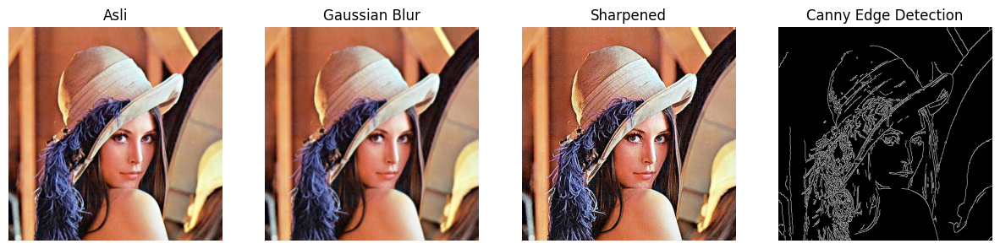

In [ ]:
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (im, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i+1)
        if len(im.shape) == 2:      # grayscale
            plt.imshow(im, cmap='gray')
        else:                        # warna (BGR -> RGB)
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
    plt.show()

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)

show_side_by_side([img, blur, sharpened, edges],
                  ['Asli', 'Gaussian Blur', 'Sharpened', 'Canny Edge Detection'])

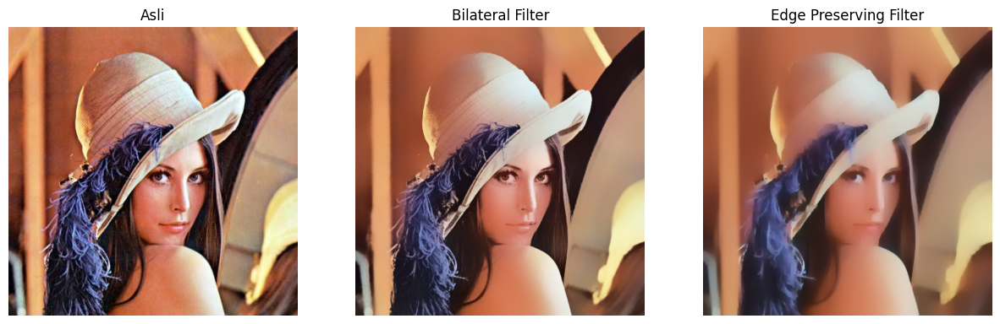

In [ ]:
bilateral = cv.bilateralFilter(img, 50, 100, 100)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ['Asli', 'Bilateral Filter', 'Edge Preserving Filter'])

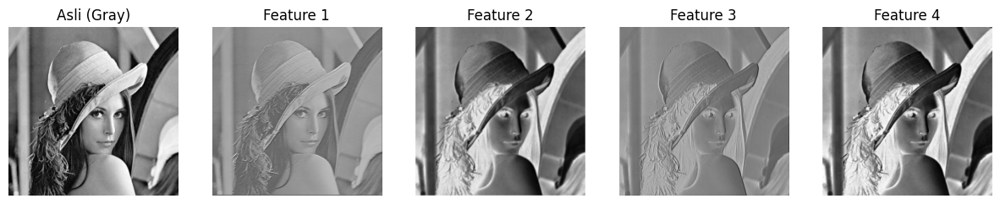

In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps,
                  ['Asli (Gray)'] + [f'Feature {i+1}' for i in range(len(feature_maps))])

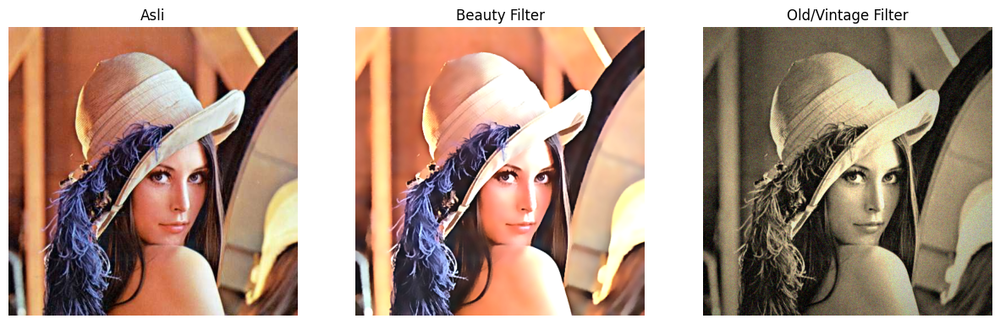

In [ ]:
# ===== 1. Beauty Filter =====
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened_b = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)   # unsharp masking

alpha = 1.2   # contrast
beta = 15     # brightness
beauty = cv.convertScaleAbs(sharpened_b, alpha=alpha, beta=beta)

# ===== 2. Old/Vintage Filter =====
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img],
                  ['Asli', 'Beauty Filter', 'Old/Vintage Filter'])

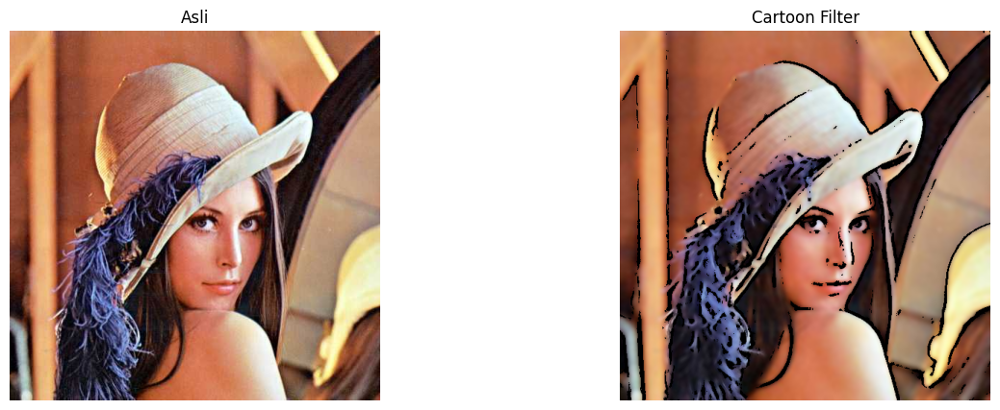

In [ ]:
# Step 1: deteksi tepi (median blur dulu agar lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges_c = cv.adaptiveThreshold(gray_blur, 255,
                               cv.ADAPTIVE_THRESH_MEAN_C,
                               cv.THRESH_BINARY, 9, 9)

# Step 2: bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges_c)

show_side_by_side([img, cartoon], ['Asli', 'Cartoon Filter'])

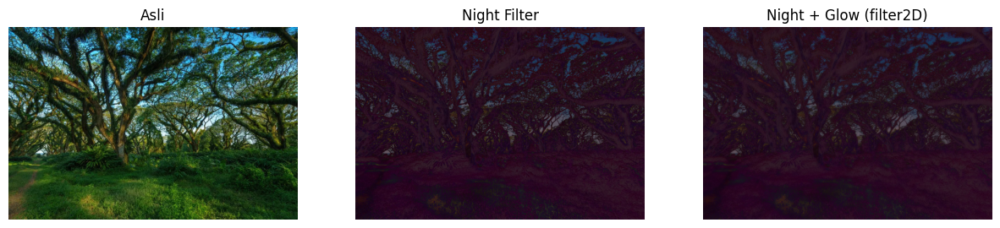

In [ ]:
scene = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020059/djawatan.jpg')
if scene is None:
    scene = img.copy()

# Step 1: gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(scene, alpha=0.6, beta=-40)

# Step 2: tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))   # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: efek glow dengan filter2D (blur kernel)
kernel_glow = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel_glow)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([scene, night, night_glow],
                  ['Asli', 'Night Filter', 'Night + Glow (filter2D)'])

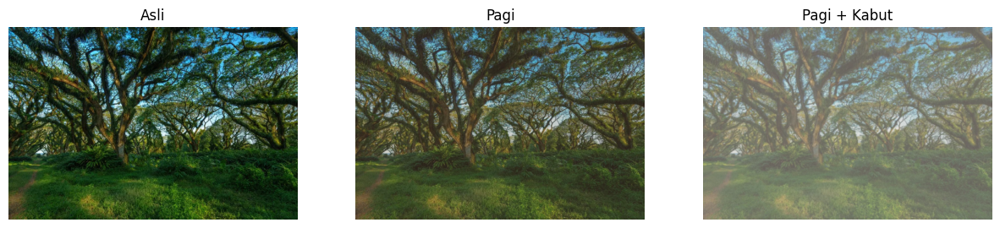

In [ ]:
# Step 1: kurangi kontras dan cerahkan
soft = cv.convertScaleAbs(scene, alpha=0.9, beta=20)

# Step 2: tambahkan warm tone (kemerahan/oranye)
warm_tint = np.full_like(soft, (40, 70, 120))   # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: tambahkan haze (kabut tipis) dengan filter2D
k = cv.getGaussianKernel(3, 3)
k = k @ k.T                                      # jadikan kernel 2D
kabut = cv.filter2D(pagi, -1, k)

# Layer putih agar kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([scene, pagi, kabut], ['Asli', 'Pagi', 'Pagi + Kabut'])

**TUGAS PRAKTIKUM**

**Tugas 1**

a. menambahkan noise salt and pepper ke citra grayscale

In [ ]:
def add_salt_pepper(image, amount=0.05):
    noisy = image.copy()
    r = np.random.random(image.shape)
    noisy[r < amount/2] = 0          # pepper (hitam)
    noisy[r > 1 - amount/2] = 255    # salt (putih)
    return noisy

noisy = add_salt_pepper(img_gray, amount=0.05)

b. menerapkan Mean Filter 3x3 dan Median Filter 3x3

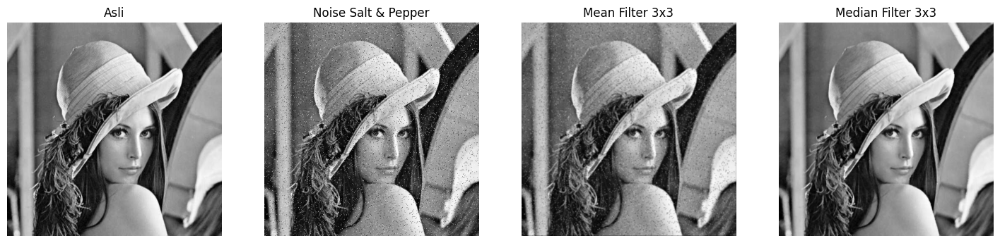

In [ ]:
mean_k = np.ones((3,3)) / 9
mean_res = filter_citra(noisy, mean_k)
median_res = cv.medianBlur(noisy, 3)

show_side_by_side([img_gray, noisy, mean_res, median_res],
                  ['Asli', 'Noise Salt & Pepper', 'Mean Filter 3x3', 'Median Filter 3x3'],
                  figsize=(18,5))

In [ ]:
def mse(a, b):
    return np.mean((a.astype(float) - b.astype(float))**2)

def psnr(a, b):
    return 10 * np.log10(255**2 / mse(a, b))

for nama, im_ in [('Noisy', noisy), ('Mean 3x3', mean_res), ('Median 3x3', median_res)]:
    print(f'{nama:<12} MSE={mse(img_gray, im_):8.2f}  PSNR={psnr(img_gray, im_):6.2f} dB')

Noisy        MSE= 1008.71  PSNR= 18.09 dB
Mean 3x3     MSE=  181.73  PSNR= 25.54 dB
Median 3x3   MSE=   31.81  PSNR= 33.11 dB


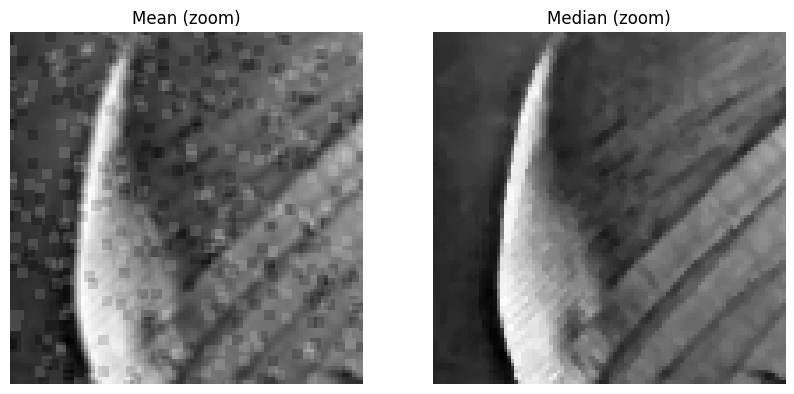

In [ ]:
y, x, s = 100, 100, 100
show_side_by_side([mean_res[y:y+s, x:x+s], median_res[y:y+s, x:x+s]],
                  ['Mean (zoom)', 'Median (zoom)'], figsize=(10,5))

**c. Analisis**


*   Mean filter mengganti piksel dengan rata-rata 9 tetangganya. Piksel noise bernilai ekstrem (0 atau 255), jadi ikut menarik rata-rata. Satu piksel putih menaikkan hasil sekitar 28 level. Noise tidak hilang, hanya menyebar menjadi bercak abu-abu buram, dan tepi ikut mengabur.
*   Median filter mengambil nilai tengah dari 9 piksel yang diurutkan. Selama noise di jendela kurang dari separuh, nilai ekstrem berada di ujung urutan dan tidak pernah terpilih, sehingga noise benar-benar terbuang. Nilai hasilnya selalu piksel asli, jadi tepi tetap relatif tajam.


*   Kesimpulan: untuk noise impulsif seperti salt and pepper, median jauh lebih efektif. Mean lebih cocok untuk noise yang sebarannya halus.






**Tugas 2: Ukuran Kernel Sharpening Terbaik (3x3 vs 5x5)**

**a. Buat kernel 3x3 dan 5x5**

In [ ]:
sharp3 = np.array([[0,-1,0],
                   [-1,5,-1],
                   [0,-1,0]], dtype=float)

sharp5 = np.array([[-1,-1,-1,-1,-1],
                   [-1, 2, 2, 2,-1],
                   [-1, 2, 8, 2,-1],
                   [-1, 2, 2, 2,-1],
                   [-1,-1,-1,-1,-1]], dtype=float) / 8

print(sharp3.sum(), sharp5.sum())   # keduanya 1.0 (kecerahan terjaga)

1.0 1.0


**b. menerapkan pada citra yang sedikit buram**

In [ ]:
blurry = cv.GaussianBlur(img_gray, (0,0), 2)
noise = np.random.normal(0, 3, blurry.shape)
blurry_noisy = np.clip(blurry + noise, 0, 255).astype(np.uint8)

res3 = filter_citra(blurry_noisy, sharp3)
res5 = filter_citra(blurry_noisy, sharp5)

show_side_by_side([img_gray, blurry_noisy, res3, res5],
                  ['Asli (tajam)', 'Buram + noise', 'Sharpen 3x3', 'Sharpen 5x5'],
                  figsize=(18,5))

**c. Evaluasi: kejelasan tepi vs noise**

In [ ]:

print(f'{"Citra":<16}{"Tepi":>8}{"Noise":>8}{"PSNR":>8}')
for nama, im_ in [('Buram+noise', blurry_noisy), ('Sharpen 3x3', res3), ('Sharpen 5x5', res5)]:
    print(f'{nama:<16}{edge_clarity(im_):>8.2f}{noise_level(im_):>8.2f}{psnr(img_gray, im_):>8.2f}')

Citra               Tepi   Noise    PSNR
Buram+noise        39.54    3.09   25.88
Sharpen 3x3        71.84   16.15   21.84
Sharpen 5x5        55.17    4.21   26.49


**Tugas 3: Filter Kartun.**

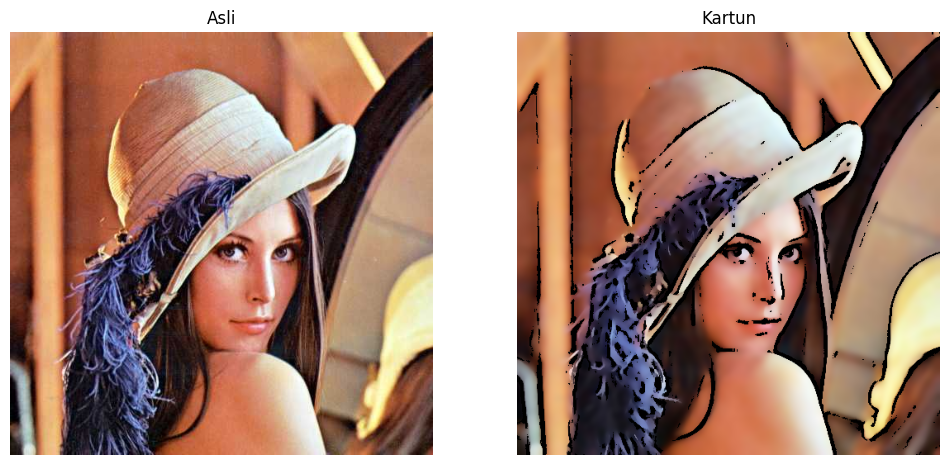

In [ ]:
def show_side_by_side(images, titles, figsize=(12,6)):
    plt.figure(figsize=figsize)
    for i, (im_, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i+1)
        if len(im_.shape) == 2:
            plt.imshow(im_, cmap='gray')
        else:
            plt.imshow(cv.cvtColor(im_, cv.COLOR_BGR2RGB))
        plt.title(t)
        plt.axis('off')
    plt.show()

def kartun(image):
    # 1. Penghalusan warna dengan Bilateral Filter (diulang 3x agar warna makin rata)
    warna = image.copy()
    for _ in range(3):
        warna = cv.bilateralFilter(warna, d=9, sigmaColor=75, sigmaSpace=75)

    # 2. Deteksi garis tepi dengan Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray = cv.medianBlur(gray, 7)   # kurangi noise agar garis lebih bersih
    garis = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, blockSize=9, C=9)

    # 3. Gabungkan warna dan garis dengan operasi logika AND
    return cv.bitwise_and(warna, warna, mask=garis)

hasil_kartun = kartun(img)
show_side_by_side([img, hasil_kartun], ['Asli', 'Kartun'], figsize=(12,6))